<a href="https://colab.research.google.com/github/FPetterini/econometria/blob/main/Poisson.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratório 5 — Contagens, média condicional e regressão de Poisson

**Econometria I · Capítulo 15 · Aula 5 de 5 · 60 minutos**

**Referência:** Gujarati e Porter (2011), seção 15.12, pp. 573–576; síntese das extensões da seção 15.13. Aplicação didática simulada com número de consultas médicas.

| Tempo | Etapa |
|---|---|
| 0–10 min | Distinguir uma contagem de uma variável binária |
| 10–20 min | Entender a média e a distribuição de Poisson |
| 20–32 min | Estimar e interpretar os coeficientes |
| 32–42 min | Calcular médias e probabilidades |
| 42–50 min | Examinar dispersão e comparar a matriz usual com HC0 |
| 50–58 min | Resolver o exercício |
| 58–60 min | Escolher o modelo conforme a variável dependente |

## Como trabalhar

Abra este arquivo `.ipynb` no [Google Colab](https://colab.research.google.com/), salve uma cópia e execute as células na ordem com ▶ ou **Shift + Enter**. Dê dois cliques nas células **Sua resposta** para escrever. Cada notebook funciona sozinho, com dados ou simulação incorporados; não exige montar o Drive.

O código dos exemplos está pronto. No exercício, substitua os campos `None` pelos valores solicitados. As células avisam quando falta preencher algo, sem interromper a execução. As respostas de referência estão recolhidas ao final.

In [ ]:
import importlib.util
import subprocess
import sys
if importlib.util.find_spec("statsmodels") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "statsmodels"])

from io import StringIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import norm, poisson
from scipy.special import expit
from IPython.display import display, HTML

%matplotlib inline
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 12)
print("Ambiente pronto. Execute as células na ordem.")

Ambiente pronto. Execute as células na ordem.


## 1. O que estamos contando? · 0–10 min

Pense no **número de consultas médicas de uma pessoa durante 12 meses**: 0, 1, 2, 3 e assim por diante. É uma variável discreta de contagem. Diferentemente de uma variável binária, ela conserva a informação sobre quantas vezes o evento ocorreu.

O capítulo cita consultas médicas, viagens e outros exemplos de contagem; sua aplicação numérica trata de quedas entre idosos. Aqui usaremos uma **base simulada de 600 pessoas**, com variáveis fáceis de interpretar no contexto brasileiro. Os números não descrevem um levantamento real de saúde.

| Variável | Significado |
|---|---|
| `consultas` | Número de consultas nos mesmos 12 meses para todas as pessoas |
| `idade` | Idade em anos |
| `idade10` | $(idade-40)/10$: uma unidade equivale a dez anos de idade |
| `cronica` | 1 para presença de uma condição crônica; 0 para ausência |

Uma pessoa de 30 anos tem `idade10 = -1`; uma de 40, zero; uma de 50, um. A centralização facilita interpretar o intercepto e não altera a natureza da contagem.

Uma contagem zero é um resultado possível do processo. Não a trataremos como censura de uma quantidade negativa, como fizemos no Tobit.

In [ ]:
rng = np.random.default_rng(202605)
n = 600
dados = pd.DataFrame({
    "idade": rng.integers(18, 76, n),
    "cronica": rng.binomial(1, 0.35, n),
})
dados["idade10"] = (dados["idade"] - 40) / 10
regressores = ["idade10", "cronica"]
X = sm.add_constant(dados[regressores], has_constant="add")
beta_verdadeiro = np.array([0.25, 0.18, 0.60])
dados["media_verdadeira"] = np.exp(X.to_numpy() @ beta_verdadeiro)
dados["consultas"] = rng.poisson(dados["media_verdadeira"])
y = dados["consultas"]
display(dados.head(6).round(3))
print(f"Pessoas: {len(dados)} | Sem consultas: {(y == 0).mean():.1%}")
print(f"Média amostral: {y.mean():.3f} | Variância amostral: {y.var(ddof=1):.3f}")

Pessoas: 600 | Sem consultas: 16.7%
Média amostral: 1.918 | Variância amostral: 2.362


,idade,cronica,idade10,media_verdadeira,consultas
0,25,1,-1.5,1.786,1
1,36,0,-0.4,1.195,0
2,55,1,1.5,3.065,3
3,36,1,-0.4,2.177,2
4,60,1,2.0,3.353,4
5,70,0,3.0,2.203,4


## 2. Modelando a média de uma contagem · 10–20 min

Na Poisson, $\lambda_i$ representa o número médio esperado para um perfil. Não é uma probabilidade: pode ser 0,8; 2,5; 6 etc. Embora cada pessoa tenha um número inteiro de consultas, a média de pessoas com o mesmo perfil pode ser fracionária.

A distribuição de Poisson atribui probabilidades aos inteiros não negativos:

$$P(Y_i=k\mid X_i)=\frac{e^{-\lambda_i}\lambda_i^k}{k!},\qquad k=0,1,2,\ldots.$$

No modelo de regressão, adotamos:

$$\lambda_i=E(Y_i\mid X_i)=\exp(\beta_1+\beta_2\,idade10_i+\beta_3\,cronica_i).$$

O exponencial garante uma média positiva. O índice linear representa o **logaritmo da média**, e não o logaritmo da contagem observada. Não precisamos calcular $\ln(Y)$ e descartar os zeros.

Se a distribuição condicional é Poisson, também vale:

$$\operatorname{Var}(Y_i\mid X_i)=E(Y_i\mid X_i)=\lambda_i.$$

Essa igualdade é **condicional ao perfil**. Pessoas diferentes podem ter médias e variâncias diferentes. Portanto, comparar a média e a variância brutas de toda a base não basta para diagnosticar sobredispersão condicional.

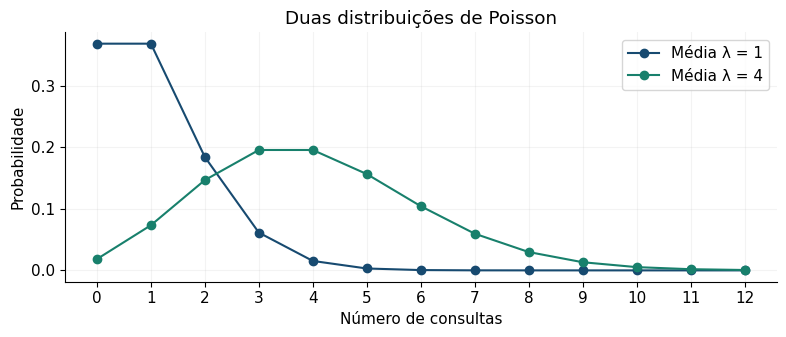

In [ ]:
valores = np.arange(0, 13)
fig, ax = plt.subplots(figsize=(8, 3.5))
for media, cor in [(1, "#174a70"), (4, "#18806c")]:
    ax.plot(valores, poisson.pmf(valores, media), marker="o", color=cor,
            label=f"Média λ = {media}")
ax.set(xlabel="Número de consultas", ylabel="Probabilidade", title="Duas distribuições de Poisson")
ax.set_xticks(valores)
ax.legend()
ax.grid(alpha=0.15)
fig.tight_layout()
plt.show()

## 3. Estimação e interpretação · 20–32 min

O comando abaixo estima uma regressão de Poisson com ligação log, usando a especificação exponencial apresentada. A tabela informa coeficientes, erros padrão e estatísticas z de referência normal assintótica. Não estamos supondo que a contagem ou o erro seja normal.

Sob distribuição condicional correta, identificação, exogeneidade compatível com a especificação e condições usuais de amostragem, a máxima verossimilhança é consistente. Não supomos ausência de viés em amostra finita.

In [ ]:
def tabela_inferencia(resultado, nomes):
    return pd.DataFrame({
        "Coeficiente": np.asarray(resultado.params),
        "Erro padrão": np.asarray(resultado.bse),
        "z (H0: coef. = 0)": np.asarray(resultado.tvalues),
        "p-valor": np.asarray(resultado.pvalues),
    }, index=nomes)

In [ ]:
modelo = sm.GLM(y, X, family=sm.families.Poisson()).fit()
display(tabela_inferencia(modelo, X.columns).style.format("{:.4f}"))
print(f"Convergência: {modelo.converged}")

efeitos_multiplicativos = pd.DataFrame({
    "Coeficiente": modelo.params[regressores],
    "Multiplicador da média exp(coef.)": np.exp(modelo.params[regressores]),
    "Variação percentual exata": 100*np.expm1(modelo.params[regressores]),
})
display(efeitos_multiplicativos.style.format("{:.3f}"))

Convergência: True


,Coeficiente,Erro padrão,z (H0: coef. = 0),p-valor
const,0.2512,0.0462,5.4370,0.0000
idade10,0.1685,0.0179,9.4206,0.0000
cronica,0.6050,0.0590,10.2523,0.0000


,Coeficiente,Multiplicador da média exp(coef.),Variação percentual exata
idade10,0.168,1.183,18.348
cronica,0.605,1.831,83.127


### Coeficiente, multiplicador e variação percentual

Se um coeficiente fosse 0,6, o multiplicador seria $e^{0,6}\approx1,822$: a média seria aproximadamente 82,2% maior, mantendo o resto constante. A variação percentual exata é **$100[e^{\beta_j}-1]$**; usar $100\beta_j$ é apenas uma aproximação para coeficientes pequenos.

Para `idade10`, uma unidade corresponde a **dez anos**, não um ano. Para `cronica`, a comparação é de 0 para 1. Nesta especificação sem interações, o multiplicador é constante, mas a diferença em número de consultas depende da média inicial.

O intercepto representa o logaritmo da média aos 40 anos e sem condição crônica. Exponenciá-lo fornece essa média de referência.

Como os dados foram simulados, conhecemos os parâmetros usados: 0,25 no intercepto, 0,18 em idade10 e 0,60 em cronica. As estimativas variam em torno deles; não precisam ser iguais em uma amostra.

## 4. Média esperada e probabilidade de um evento · 32–42 min

Prever uma média de 2,5 consultas não significa uma probabilidade de 250%. Para obter uma probabilidade, usamos a distribuição, por exemplo:

$$P(Y_i=0\mid X_i)=e^{-\lambda_i};\qquad P(Y_i\geq1\mid X_i)=1-e^{-\lambda_i}.$$

Também podemos somar as probabilidades de 0, 1 e 2 para obter $P(Y_i\leq2\mid X_i)$. O pacote calcula essa soma pela distribuição acumulada.

In [ ]:
def prever_poisson(perfis):
    pe = perfis.copy()
    pe["idade10"] = (pe["idade"] - 40) / 10
    Xp = sm.add_constant(pe[regressores], has_constant="add")
    media = modelo.predict(Xp)
    pe["media_consultas"] = media
    pe["prob_zero"] = poisson.pmf(0, media)
    pe["prob_ao_menos_uma"] = 1 - pe["prob_zero"]
    pe["prob_ate_duas"] = poisson.cdf(2, media)
    return pe

perfis = pd.DataFrame({"idade": [40, 40, 50], "cronica": [0, 1, 1]}, index=["A", "B", "C"])
previsoes = prever_poisson(perfis)
display(previsoes.style.format({
    "media_consultas": "{:.3f}", "prob_zero": "{:.2%}",
    "prob_ao_menos_uma": "{:.2%}", "prob_ate_duas": "{:.2%}",
}))

,idade,cronica,idade10,media_consultas,prob_zero,prob_ao_menos_uma,prob_ate_duas
A,40,0,0.000000,1.286,27.65%,72.35%,86.04%
B,40,1,0.000000,2.354,9.50%,90.50%,58.17%
C,50,1,1.000000,2.786,6.17%,93.83%,47.28%


### Efeito marginal em número de consultas

Para uma variável contínua $x_j$, a derivada da média é $\beta_j\lambda_i$. Assim, para **um ano de idade**, o efeito local é $\beta_{idade10}\lambda_i/10$.

Para a dummy crônica, use a diferença exata entre duas médias previstas: média com `cronica = 1` menos média com `cronica = 0`, mantendo a idade. A derivada contínua não representa automaticamente essa passagem de 0 para 1.

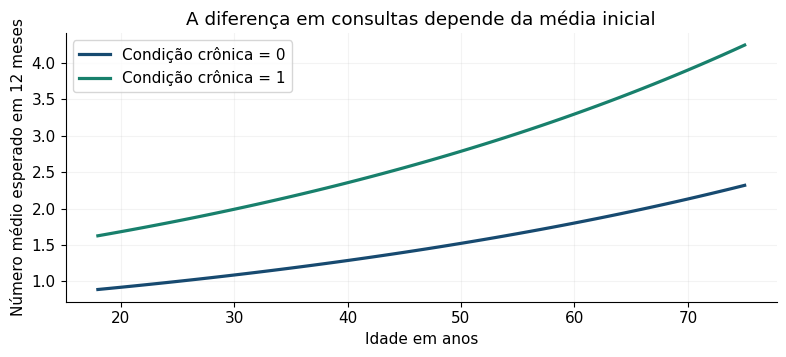

In [ ]:
grade = pd.DataFrame({"idade": np.arange(18, 76), "cronica": 0})
fig, ax = plt.subplots(figsize=(8, 3.7))
for cronica, cor in [(0, "#174a70"), (1, "#18806c")]:
    pe = prever_poisson(grade.assign(cronica=cronica))
    ax.plot(pe.idade, pe.media_consultas, color=cor, linewidth=2.3, label=f"Condição crônica = {cronica}")
ax.set(xlabel="Idade em anos", ylabel="Número médio esperado em 12 meses",
       title="A diferença em consultas depende da média inicial")
ax.legend()
ax.grid(alpha=0.15)
fig.tight_layout()
plt.show()

## 5. Dispersão e matriz de covariância · 42–50 min

O modelo usual utiliza a igualdade entre média e variância condicionais. Uma razão de dispersão de Pearson próxima de um é compatível com essa hipótese, embora não seja uma prova de especificação correta. Vamos examinar o indicador e comparar os erros padrão usuais com uma sanduíche HC0.

In [ ]:
modelo_hc0 = sm.GLM(y, X, family=sm.families.Poisson()).fit(cov_type="HC0")
dispersao = modelo.pearson_chi2 / modelo.df_resid
comparacao_cov = pd.concat({
    "Usual Poisson": tabela_inferencia(modelo, X.columns),
    "Sanduíche HC0": tabela_inferencia(modelo_hc0, X.columns),
}, names=["Matriz", "Parâmetro"])
display(comparacao_cov.style.format("{:.4f}"))
print(f"Dispersão de Pearson: {dispersao:.3f}")

Dispersão de Pearson: 0.921


### Um contraste controlado: mesma média, variância adicional

Para enxergar a distinção entre média e variância, a célula pronta abaixo cria outra contagem. Ela acrescenta heterogeneidade aleatória independente dos regressores, com média um, multiplicando a média original antes do sorteio.

Na nova contagem, a média condicional continua sendo $\lambda_i$, mas a variância passa a $\lambda_i+0,8\lambda_i^2$. A distribuição condicional já não é Poisson. Se a média exponencial estiver corretamente especificada e as condições usuais forem válidas, a estimação de Poisson pode ser usada como **quase-máxima verossimilhança**, com matriz sanduíche para a inferência. Não é necessário supor que toda a distribuição seja Poisson para esse resultado sobre a média.

Esta distinção não se transfere automaticamente ao Tobit: lá, a distribuição latente participa da própria fórmula da média observada.

In [ ]:
#@title Contraste de dispersão — execute sem modificar
rng_extra = np.random.default_rng(20260599)
fator = rng_extra.gamma(shape=1/0.8, scale=0.8, size=len(dados))
dados["consultas_disp_extra"] = rng_extra.poisson(dados.media_verdadeira.to_numpy() * fator)

modelo_extra = sm.GLM(dados.consultas_disp_extra, X, family=sm.families.Poisson()).fit()
modelo_extra_hc0 = sm.GLM(dados.consultas_disp_extra, X, family=sm.families.Poisson()).fit(cov_type="HC0")
dispersao_extra = modelo_extra.pearson_chi2 / modelo_extra.df_resid
comparacao_extra = pd.DataFrame({
    "Coeficiente": modelo_extra.params,
    "EP usual Poisson": modelo_extra.bse,
    "EP sanduíche HC0": modelo_extra_hc0.bse,
    "z usual": modelo_extra.tvalues,
    "z HC0": modelo_extra_hc0.tvalues,
})
display(comparacao_extra.style.format("{:.4f}"))
print(f"Dispersão original: {dispersao:.3f} | Com heterogeneidade adicional: {dispersao_extra:.3f}")

Dispersão original: 0.921 | Com heterogeneidade adicional: 2.893


,Coeficiente,EP usual Poisson,EP sanduíche HC0,z usual,z HC0
const,0.3462,0.0442,0.0733,7.8345,4.7245
idade10,0.1857,0.0173,0.0325,10.7498,5.7061
cronica,0.5284,0.0569,0.1032,9.2933,5.1203


Dentro de cada contagem, trocar a matriz preserva os coeficientes e muda a incerteza. A matriz robusta não corrige endogeneidade nem uma média condicional errada. O diagnóstico relevante é condicional: na primeira base, a variância bruta pode superar a média bruta simplesmente porque há pessoas com médias diferentes.

As probabilidades calculadas pela distribuição de Poisson são justificadas para a primeira simulação. Na contagem com variância extra, uma média bem estimada não basta para validar as probabilidades de zero ou de outros valores calculadas como se a distribuição completa fosse Poisson.

## 6. Exercício prático · 50–58 min

**Nome:** escreva aqui.

### A. Interpretando o coeficiente · 2 min

Digite `"cronica"` e calcule a variação percentual exata na média associada à passagem de 0 para 1. Explique por que não é uma diferença em pontos percentuais de uma probabilidade.

In [ ]:
parametro_exercicio = None
if parametro_exercicio is None:
    print('Preencha parametro_exercicio com "cronica".')
else:
    b = modelo.params[parametro_exercicio]
    print(f"Coeficiente: {b:.4f}")
    print(f"Multiplicador da média: {np.exp(b):.4f}")
    print(f"Variação percentual exata: {100*np.expm1(b):.2f}%")

Preencha parametro_exercicio com "cronica".


**Sua resposta — A:** Interprete o multiplicador da média de consultas, mantendo a idade constante.

> Escreva aqui.

### B. Duas médias e uma probabilidade · 3 min

Preencha idade 40 para dois perfis: um sem condição crônica e outro com condição crônica. Compare o número médio de consultas e a probabilidade de nenhuma consulta. Uma média fracionária é um problema?

In [ ]:
idade_exercicio = None
if idade_exercicio is None:
    print("Preencha idade_exercicio com 40.")
else:
    pe = pd.DataFrame({"idade": [idade_exercicio, idade_exercicio], "cronica": [0, 1]})
    previsoes_exercicio = prever_poisson(pe)
    display(previsoes_exercicio.round(4))
    print(f"Diferença entre médias: {previsoes_exercicio.media_consultas.diff().iloc[1]:.3f} consultas.")

Preencha idade_exercicio com 40.


**Sua resposta — B:** Diferencie a contagem individual, a média condicional e a probabilidade de zero.

> Escreva aqui.

### C. Diagnóstico de dispersão · 3 min

Compare as razões de Pearson das duas simulações e os erros padrão da tabela com variância adicional. Por que a diferença entre média e variância brutas da base original não bastava para concluir que o modelo condicional estivesse errado? A HC0 conserta uma média mal especificada?

**Sua resposta — C:** Explique a importância de condicionar nos regressores e separe os pressupostos sobre média e distribuição.

> Escreva aqui.

## 7. Fechamento do capítulo · 58–60 min

Antes de escolher uma rotina, identifique a natureza de $Y$ e o mecanismo de observação:

| Variável dependente e pergunta | Modelo estudado ou extensão da seção 15.13 |
|---|---|
| Sim ou não; queremos uma probabilidade | MPL, logit ou probit |
| Valor contínuo observado com censura conhecida | Tobit, sob seus pressupostos |
| Número de ocorrências em uma exposição definida | Poisson para a distribuição ou para a média, conforme os pressupostos |
| Categorias ordenadas, como satisfação baixa/média/alta | Logit ou probit ordinal |
| Categorias sem ordem, como meio de transporte | Modelo multinomial |
| Tempo até um evento, como saída do desemprego | Modelo de duração |

As três últimas linhas são a leitura orientada da seção 15.13; não estimaremos essas extensões neste notebook. Em todos os modelos, uma correção de erro padrão exige saber qual estimador e quais pressupostos estão sendo usados.

## Conferência após resolver

<details>
<summary><strong>Abrir respostas de referência</strong></summary>

**A.** Use `parametro_exercicio = "cronica"`. O coeficiente é aproximadamente **0,6050**, seu exponencial é **1,8313** e a média de consultas é aproximadamente **83,13% maior**, mantendo a idade constante. A fórmula exata é 100 × [exp(coeficiente) − 1]; não é uma variação direta na probabilidade.

**B.** Use `idade_exercicio = 40`. Sem condição crônica, a média é aproximadamente **1,286 consulta** e a probabilidade de zero é **27,65%**. Com condição crônica, a média é aproximadamente **2,354 consultas** e a probabilidade de zero é **9,50%**. A diferença média é **1,069 consulta**. Uma média fracionária é admissível, embora as contagens individuais sejam inteiras. A média não é uma probabilidade.

**C.** A razão de Pearson é aproximadamente **0,921** na simulação original e **2,893** na contagem com heterogeneidade adicional. A primeira tem distribuição condicional Poisson por construção. A heterogeneidade das médias entre pessoas pode fazer a variância bruta superar a média bruta. A segunda tem variância condicional maior; os erros padrão robustos a refletem de outra maneira. A troca da matriz não corrige uma média errada nem endogeneidade. As probabilidades Poisson da seção 4 não são automaticamente válidas para a contagem adicional.

</details>

## Referências e relação com o livro

- **Gujarati, D. N.; Porter, D. C.** *Econometria básica*. 5. ed. Porto Alegre: AMGH, 2011. Capítulo 15, seção 15.12, pp. 573–576, e leitura orientada da seção 15.13, pp. 576–577. A aplicação de consultas médicas retoma um dos tipos de contagem mencionados no capítulo. As duas bases são simulações próprias, e não os dados do exemplo geriátrico do livro.
- As explicações e os exercícios foram redigidos para a aula. As extensões de inferência são demonstrações computacionais; não são tabelas adicionais atribuídas ao livro.
- Documentação técnica: [GLM](https://www.statsmodels.org/stable/generated/statsmodels.genmod.generalized_linear_model.GLM.html), [família Poisson](https://www.statsmodels.org/stable/generated/statsmodels.genmod.families.family.Poisson.html) e [probabilidades Poisson](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.poisson.html).